In [1]:
from google.colab import files

uploaded = files.upload()

Saving cleaned_data.csv to cleaned_data.csv


In [2]:
# Install required libraries
!pip install pandas numpy matplotlib scikit-learn nltk

In [3]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Text Processing
import string
import pickle
import re

# Counter
from collections import Counter

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [4]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [5]:
df = pd.read_csv('/content/cleaned_data.csv')

In [6]:
df.head()

,headline,label
0,former versace store clerk sues over secret 'b...,non-sarcastic
1,the 'roseanne' revival catches up to our thorn...,non-sarcastic
2,mom starting to fear son's web series closest ...,sarcastic
3,"boehner just wants wife to listen, not come up...",sarcastic
4,j.k. rowling wishes snape happy birthday in th...,non-sarcastic


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (26524, 2)

Column Names:
Index(['headline', 'label'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26524 entries, 0 to 26523
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   headline  26524 non-null  object
 1   label     26524 non-null  object
dtypes: object(2)
memory usage: 414.6+ KB


In [8]:
print(df.isnull().sum())

headline    0
label       0
dtype: int64


In [9]:
df = df.dropna()

In [10]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [11]:
df = df.drop_duplicates(subset='headline')

In [12]:
print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (26524, 2)


In [13]:
df['is_sarcastic'] = df['label'].map({
    'sarcastic': 1,
    'non-sarcastic': 0
})

In [14]:
df.head()

,headline,label,is_sarcastic
0,former versace store clerk sues over secret 'b...,non-sarcastic,0
1,the 'roseanne' revival catches up to our thorn...,non-sarcastic,0
2,mom starting to fear son's web series closest ...,sarcastic,1
3,"boehner just wants wife to listen, not come up...",sarcastic,1
4,j.k. rowling wishes snape happy birthday in th...,non-sarcastic,0


In [15]:
df = df[['headline', 'is_sarcastic']]

In [16]:
df.head()

,headline,is_sarcastic
0,former versace store clerk sues over secret 'b...,0
1,the 'roseanne' revival catches up to our thorn...,0
2,mom starting to fear son's web series closest ...,1
3,"boehner just wants wife to listen, not come up...",1
4,j.k. rowling wishes snape happy birthday in th...,0


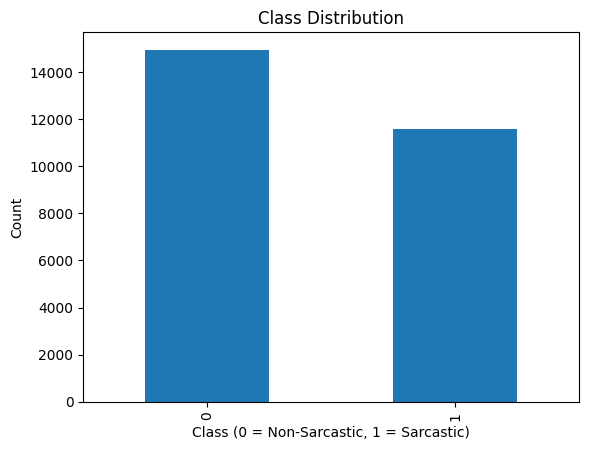

In [17]:
df['is_sarcastic'].value_counts().plot(kind='bar')

plt.title('Class Distribution')
plt.xlabel('Class (0 = Non-Sarcastic, 1 = Sarcastic)')
plt.ylabel('Count')
plt.show()

In [18]:
print(df['is_sarcastic'].value_counts())

is_sarcastic
0    14939
1    11585
Name: count, dtype: int64


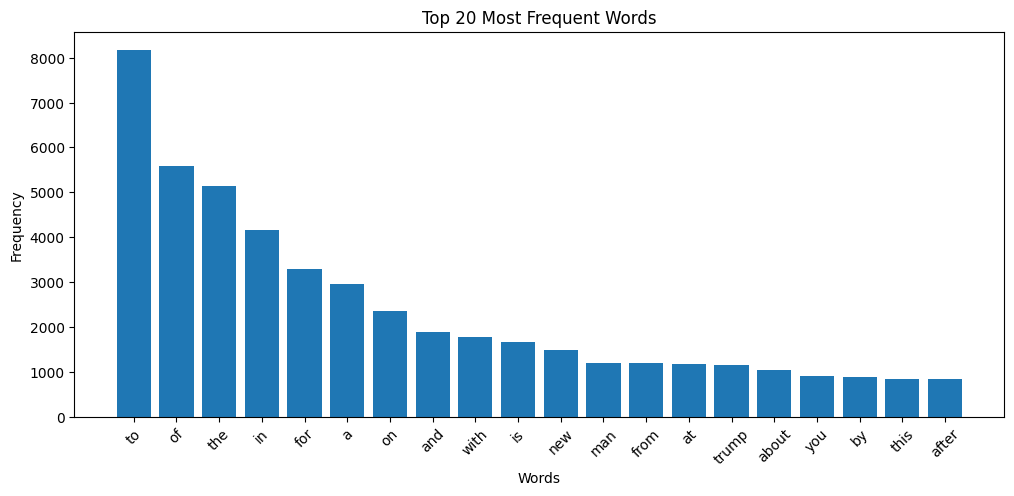

In [19]:
all_words = ' '.join(df['headline']).split()

word_freq = Counter(all_words)

common_words = dict(word_freq.most_common(20))

plt.figure(figsize=(12, 5))
plt.bar(common_words.keys(), common_words.values())

plt.xticks(rotation=45)
plt.title('Top 20 Most Frequent Words')
plt.xlabel('Words')
plt.ylabel('Frequency')

plt.show()

In [20]:
lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words('english'))

In [21]:
def clean_text(text):
    # Convert to lowercase
    text = str(text).lower()

    # Remove punctuation
    text = ''.join(
        char for char in text
        if char not in string.punctuation
    )

    # Tokenization
    words = text.split()

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [22]:
df['headline'] = df['headline'].apply(clean_text)

In [23]:
df.head()

,headline,is_sarcastic
0,former versace store clerk sue secret black co...,0
1,roseanne revival catch thorny political mood b...,0
2,mom starting fear son web series closest thing...,1
3,boehner want wife listen come alternative debt...,1
4,jk rowling wish snape happy birthday magical way,0


In [24]:
# separate input and output
X = df['headline']
y = df['is_sarcastic']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 21219
Testing Data: 5305


In [27]:
# Create TF-IDF Vectorizer
feature_range = [5000, 6000, 7000, 8000, 9000, 10000]

best_accuracy = 0
best_vectorizer = None
best_model = None

features_list = []
accuracy_list = []

In [28]:
for features in feature_range:

    print(f"\nTesting max_features = {features}")

    vectorizer = TfidfVectorizer(
        max_features=features,
        ngram_range=(1, 2),
        stop_words='english'
    )

    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    model = LogisticRegression(max_iter=1000)

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    acc = accuracy_score(y_test, y_pred)

    print("Accuracy:", acc)

    features_list.append(features)
    accuracy_list.append(acc)

    if acc > best_accuracy:
        best_accuracy = acc
        best_vectorizer = vectorizer
        best_model = model

print("\nBest Accuracy:", best_accuracy)


Testing max_features = 5000
Accuracy: 0.7851083883129123

Testing max_features = 6000
Accuracy: 0.7869934024505184

Testing max_features = 7000
Accuracy: 0.7894439208294062

Testing max_features = 8000
Accuracy: 0.7869934024505184

Testing max_features = 9000
Accuracy: 0.7866163996229971

Testing max_features = 10000
Accuracy: 0.7877474081055608

Best Accuracy: 0.7894439208294062


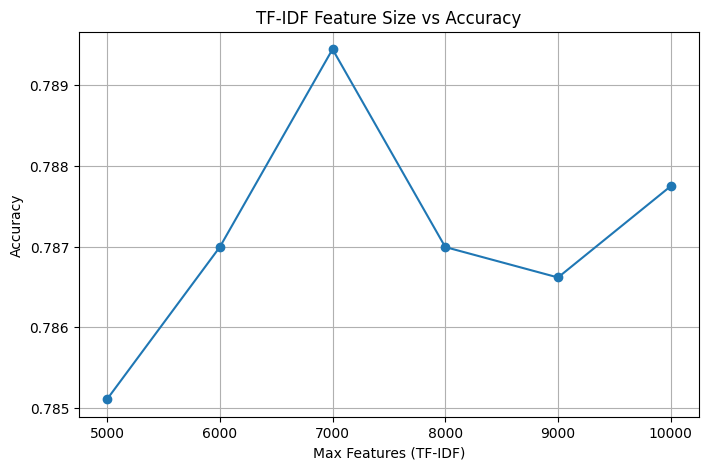

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    features_list,
    accuracy_list,
    marker='o'
)

plt.xlabel('Max Features (TF-IDF)')
plt.ylabel('Accuracy')
plt.title('TF-IDF Feature Size vs Accuracy')

plt.grid()
plt.show()

In [30]:
X_train_tfidf = best_vectorizer.transform(X_train)
X_test_tfidf = best_vectorizer.transform(X_test)

In [31]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)


# Support Vector Machine
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)


# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_tfidf, y_train)

y_pred_rf = rf_model.predict(X_test_tfidf)


# Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

In [32]:
def evaluate_model(name, y_test, y_pred):

    print("\n" + "="*40)
    print(name)
    print("="*40)

    print("Accuracy:",
          accuracy_score(y_test, y_pred))

    print("Precision:",
          precision_score(y_test, y_pred))

    print("Recall:",
          recall_score(y_test, y_pred))

    print("F1 Score:",
          f1_score(y_test, y_pred))

In [33]:
evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr
)

evaluate_model(
    "SVM",
    y_test,
    y_pred_svm
)

evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

evaluate_model(
    "Naive Bayes",
    y_test,
    y_pred_nb
)


Logistic Regression
Accuracy: 0.7894439208294062
Precision: 0.8
Recall: 0.6905481225722918
F1 Score: 0.7412555015056752

SVM
Accuracy: 0.7862393967954759
Precision: 0.7637093178778421
Recall: 0.7393180837289599
F1 Score: 0.7513157894736842

Random Forest
Accuracy: 0.760603204524034
Precision: 0.748221906116643
Recall: 0.6810530858869227
F1 Score: 0.7130591956619973

Naive Bayes
Accuracy: 0.7868049010367578
Precision: 0.7970941883767535
Recall: 0.6866637893828226
F1 Score: 0.7377695339670762


In [34]:
print("Classification Report - Logistic Regression")

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

Classification Report - Logistic Regression
              precision    recall  f1-score   support

           0       0.78      0.87      0.82      2988
           1       0.80      0.69      0.74      2317

    accuracy                           0.79      5305
   macro avg       0.79      0.78      0.78      5305
weighted avg       0.79      0.79      0.79      5305



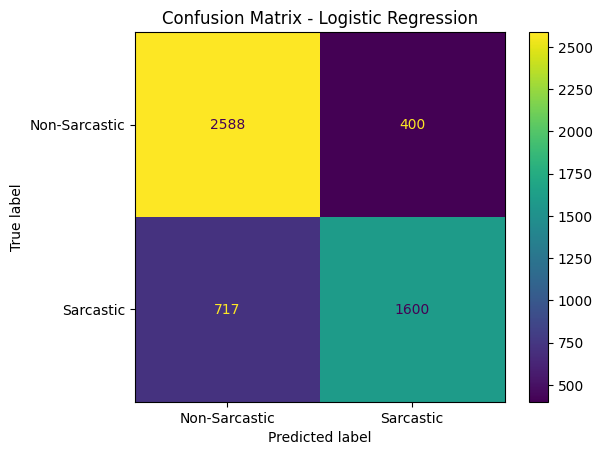

In [35]:
cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Non-Sarcastic', 'Sarcastic']
)

disp.plot()

plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [36]:
model_accuracies = {
    "Logistic Regression": accuracy_score(y_test, y_pred_lr),
    "SVM": accuracy_score(y_test, y_pred_svm),
    "Random Forest": accuracy_score(y_test, y_pred_rf),
    "Naive Bayes": accuracy_score(y_test, y_pred_nb)
}

print(model_accuracies)

{'Logistic Regression': 0.7894439208294062, 'SVM': 0.7862393967954759, 'Random Forest': 0.760603204524034, 'Naive Bayes': 0.7868049010367578}


In [37]:
best_model_name = max(
    model_accuracies,
    key=model_accuracies.get
)

print("Best Model:", best_model_name)
print("Best Accuracy:", model_accuracies[best_model_name])

Best Model: Logistic Regression
Best Accuracy: 0.7894439208294062


In [38]:
def predict_sarcasm(text):

    # Clean input text
    cleaned_text = clean_text(text)

    # Convert text to TF-IDF
    text_vector = best_vectorizer.transform([cleaned_text])

    # Predict
    prediction = best_model.predict(text_vector)[0]

    if prediction == 1:
        return "Sarcastic"
    else:
        return "Not Sarcastic"

In [39]:
sample_text = input("Enter a headline: ")

print("\nPrediction:", predict_sarcasm(sample_text))

Enter a headline:  How are you

Prediction: Not Sarcastic


In [40]:
with open('sarcasm_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

with open('vectorizer.pkl', 'wb') as f:
    pickle.dump(best_vectorizer, f)

print("Model Saved Successfully!")

Model Saved Successfully!


In [41]:
from google.colab import files

files.download('sarcasm_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
files.download('vectorizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
!git config --global user.name "hiteshwarude21"
!git config --global user.email "hiteshwarude2005@gmail.com"

In [44]:
!git clone https://github.com/hiteshwarude21/Sarcasm_Detection.git

Cloning into 'Sarcasm_Detection'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [45]:
%cd /content/Sarcasm_Detection

/content/Sarcasm_Detection


In [47]:
!ls -lah /content

total 2.3M
drwxr-xr-x 1 root root 4.0K Oct  2 15:46 .
drwxr-xr-x 1 root root 4.0K Oct  2 15:10 ..
-rw-r--r-- 1 root root 1.9M Oct  2 15:38 cleaned_data.csv
drwxr-xr-x 4 root root 4.0K Sep 16 13:26 .config
drwxr-xr-x 2 root root 4.0K Oct  2 15:33 .ipynb_checkpoints
drwxr-xr-x 1 root root 4.0K Sep 16 13:26 sample_data
drwxr-xr-x 3 root root 4.0K Oct  2 15:46 Sarcasm_Detection
-rw-r--r-- 1 root root  56K Oct  2 15:43 sarcasm_model.pkl
-rw-r--r-- 1 root root 257K Oct  2 15:43 vectorizer.pkl
